# MiniJev: a small character-level decider

This notebook builds a small decision model from prepared Geography, Physics, and Computer Science records.

We will load the records, encode their character sequences, visualize the attention mask, build the model, train it, and read its evaluation results.


## The data and prompt format

Each record contains a question and four possible answers. The model learns to point to one answer.

The prepared files contain 5,760 training records, 720 validation records, and 288 fact-OOD records. Validation changes the choices and their order while keeping the same facts. Fact-OOD uses different facts and is only a secondary diagnostic.

A prompt looks like this: `Q:question|O:first answer;O:second answer;O:third answer;O:fourth answer;A`. The question is shared context. Each option is its own branch, and `A` is the decision point.


## Setup

`RUN_FACT_OOD` is an optional secondary diagnostic. The main walkthrough always evaluates train and validation records; fact-OOD evaluation is disabled by default.


In [2]:
from pathlib import Path
import random
import sys

# Run this notebook from notebooks/ so its relative paths work.
sys.path.insert(0, str(Path('../utils').resolve()))
from bitsy_jev_util import load_records

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# Prefer CUDA, then Apple Metal (MPS), then CPU.
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print('device:', device)

Matplotlib is building the font cache; this may take a moment.


device: cuda


In [3]:
train_path = Path('../data/multi_domain_qa_train.tsv')
validation_path = Path('../data/multi_domain_qa_validation.tsv')
fact_ood_path = Path('../data/multi_domain_qa_fact_ood.tsv')

OPTION_COUNT = 4
CHANCE_ACCURACY = 1 / OPTION_COUNT
DOMAIN_NAMES = ('geography', 'physics', 'computer_science')

block_size, batch_size = 256, 32
n_embed, n_head, n_layers, dropout = 256, 4, 4, 0.1
max_iterations, eval_interval = 1500, 250
RUN_FACT_OOD = False
learning_rate = 3e-4
CONTEXT, DECIDE, PAD = -2, -1, -3

## Load prepared records

The data-generation script prepares the records. This notebook loads them and uses the fields needed by the model.


In [4]:
# Fact-OOD records are loaded with the prepared data, but used only when
# RUN_FACT_OOD enables the optional secondary diagnostic.
train_records, validation_records, fact_ood_records = map(
    load_records,
    (train_path, validation_path, fact_ood_path),
)

## Build a character vocabulary

The model maps each character in the training prompts to an integer.


In [5]:
# Fit the character vocabulary on training prompts only.
vocab = sorted(set(''.join(row['prompt'] for row in train_records)))
stoi = {ch: i for i, ch in enumerate(vocab)}
vocab_size = len(vocab)
print('vocabulary:', vocab_size, ''.join(vocab))

encode = lambda text: [stoi[ch] for ch in text]


vocabulary: 33  :;AOQabcdefghijklmnopqrstuvwxyz|


## Encode the question and its option branches

The encoder gives the question a shared role, gives each option its own role, and places the decision state after the options. 

Here is a small example. The question comes first, then four option branches, and finally the decision character `A`.

Input:
```text
Q:what is two plus two|O:three;O:four;O:five;O:six;A
```
The detailed encoding is below. `physical` is the character's index in the whole prompt.

Shared question/context (`C`):
```text
char  token  role  logical  physical
Q        5     C        0         0
:        1     C        1         1
w       28     C        2         2
h       13     C        3         3
a        6     C        4         4
t       25     C        5         5
space    0     C        6         6
i       14     C        7         7
s       24     C        8         8
space    0     C        9         9
t       25     C       10        10
w       28     C       11        11
o       20     C       12        12
space    0     C       13        13
p       21     C       14        14
l       17     C       15        15
u       26     C       16        16
s       24     C       17        17
space    0     C       18        18
t       25     C       19        19
w       28     C       20        20
o       20     C       21        21
|       32     C       22        22
```

Option branches (the `O:` prefix and ending `;` belong to the branch):
```text
char  token  role  logical  physical
O        4    O0       23        23
:        1    O0       24        24
t       25    O0       25        25
h       13    O0       26        26
r       23    O0       27        27
e       10    O0       28        28
e       10    O0       29        29
;        2    O0       30        30
O        4    O1       23        31
:        1    O1       24        32
f       11    O1       25        33
o       20    O1       26        34
u       26    O1       27        35
r       23    O1       28        36
;        2    O1       29        37
O        4    O2       23        38
:        1    O2       24        39
f       11    O2       25        40
i       14    O2       26        41
v       27    O2       27        42
e       10    O2       28        43
;        2    O2       29        44
O        4    O3       23        45
:        1    O3       24        46
s       24    O3       25        47
i       14    O3       26        48
x       29    O3       27        49
;        2    O3       28        50
```

Decision character (`D`):
```text
char  token  role  logical  physical
A        3     D       31        51
```

The token IDs come from the training character vocabulary, so they can change if the vocabulary changes. Logical position IDs are not physical character indexes. The shared question/context positions advance normally. Each option branch restarts at the shared context length, so option characters reuse logical positions even though they have different physical positions. The final `A` gets the decision position after the longest option.

- `C` is the shared question/context.
- `O0` through `O3` identify the four option branches, including each branch's `O:` prefix and ending `;`.
- `D` marks the final decision character `A`.
- Every character also gets an integer token ID and a logical position.
- Each option branch restarts its logical positions after the shared context, while its characters still occupy separate physical positions.


### Encode one record


In [6]:
# Encode each record ONCE, reusing the structural positions the parser already
# produced (`option_positions` are the pointer keys; the final 'A' is the query).
def encode_record(record):
    prompt = record['prompt']
    context_length = prompt.index('O:')
    ids = torch.tensor(encode(prompt))
    roles = torch.full((len(ids),), CONTEXT)
    positions = torch.arange(len(ids))

    previous, longest_option_length = context_length, 0
    for option_id, terminal in enumerate(record['option_positions']):
        span_length = terminal - previous + 1
        roles[previous:terminal + 1] = option_id
        positions[previous:terminal + 1] = torch.arange(
            context_length, context_length + span_length
        )
        longest_option_length = max(longest_option_length, span_length)
        previous = terminal + 1

    roles[-1] = DECIDE
    positions[-1] = context_length + longest_option_length
    return {
        'ids': ids,
        'roles': roles,
        'positions': positions,
        'terminals': torch.tensor(record['option_positions']),
        'decide': len(ids) - 1,
        'label': record['label'],
    }


### Pack records into a batch

A `PackedBatch` keeps the tensors needed by the model together. Padding makes records of different lengths fit one rectangular tensor.


In [7]:
from typing import NamedTuple

from torch.nn.utils.rnn import pad_sequence


class PackedBatch(NamedTuple):
    input_ids: torch.Tensor
    role_ids: torch.Tensor
    position_ids: torch.Tensor
    option_positions: torch.Tensor
    decide_positions: torch.Tensor
    labels: torch.Tensor


# Encode the whole dataset once (bitsy encodes its text once); batching then
# only samples, pads, and stacks.
train_encoded = [encode_record(row) for row in train_records]
validation_encoded = [encode_record(row) for row in validation_records]
fact_ood_encoded = [encode_record(row) for row in fact_ood_records]


# Pad a list of pre-encoded records into one rectangular batch.
def collate(rows):
    return PackedBatch(
        pad_sequence([r['ids'] for r in rows], batch_first=True).to(device),
        pad_sequence(
            [r['roles'] for r in rows], batch_first=True, padding_value=PAD
        ).to(device),
        pad_sequence([r['positions'] for r in rows], batch_first=True).to(device),
        torch.stack([r['terminals'] for r in rows]).to(device),
        torch.tensor([r['decide'] for r in rows], device=device),
        torch.tensor([r['label'] for r in rows], device=device),
    )


def get_batch(encoded, batch_size, rng):
    rows = [encoded[rng.randrange(len(encoded))] for _ in range(batch_size)]
    return collate(rows)

In [8]:
probe_rng = random.Random(2025)
inspection_rows = [
    train_records[probe_rng.randrange(len(train_records))] for _ in range(2)
]
inspection_inputs = collate([encode_record(row) for row in inspection_rows])
print('tensor shapes:', [tuple(x.shape) for x in inspection_inputs])
row = inspection_rows[0]
terms0 = inspection_inputs.option_positions[0].detach().cpu()
label0 = inspection_inputs.labels[0].item()
print('prompt:', row['prompt'])
print('options:', list(enumerate(row['options'])))
print('terminals:', terms0.tolist(), 'correct:', label0)


tensor shapes: [(2, 127), (2, 127), (2, 127), (2, 4), (2,), (2,)]
prompt: Q:which answer is associated with foreign key and represents|O:program execution;O:table relationship;O:queue;O:circular wait;A
options: [(0, 'program execution'), (1, 'table relationship'), (2, 'queue'), (3, 'circular wait')]
terminals: [80, 101, 109, 125] correct: 1


## The structured attention mask

The mask is causal. Question characters can be shared, an option branch can read the question and itself, and the decision state can read all earlier real characters. A `1` means attention is allowed, and a `0` means it is blocked. The attention layer changes blocked entries to `-inf` immediately before softmax.


In [9]:
class StructuredAttentionMask(nn.Module):
    def __init__(self, max_length):
        super().__init__()
        causal = torch.tril(
            torch.ones(max_length, max_length, dtype=torch.bool)
        )
        self.register_buffer('causal', causal, persistent=False)

    def forward(self, roles, dtype):
        _, length = roles.shape
        causal = self.causal[:length, :length]
        query_real, key_real = (
            roles[:, :, None] != PAD,
            roles[:, None, :] != PAD,
        )
        key_is_option = roles[:, None, :] >= 0
        query_is_decide = roles[:, :, None] == DECIDE
        same_option = roles[:, :, None] == roles[:, None, :]
        allow = causal & query_real & key_real & (
            ~key_is_option | query_is_decide | same_option
        )
        diagonal = torch.eye(
            length, dtype=torch.bool, device=roles.device
        )[None]
        allow = allow | ((roles[:, :, None] == PAD) & diagonal)
        return allow[:, None].to(dtype=dtype)

shared_attention_mask = StructuredAttentionMask(block_size).to(device)


### Who may attend to whom

This small template makes the pattern easy to see without using a real record. It goes through the same character encoder as the data.

Rows are query characters and columns are key characters. Black means the read is allowed.


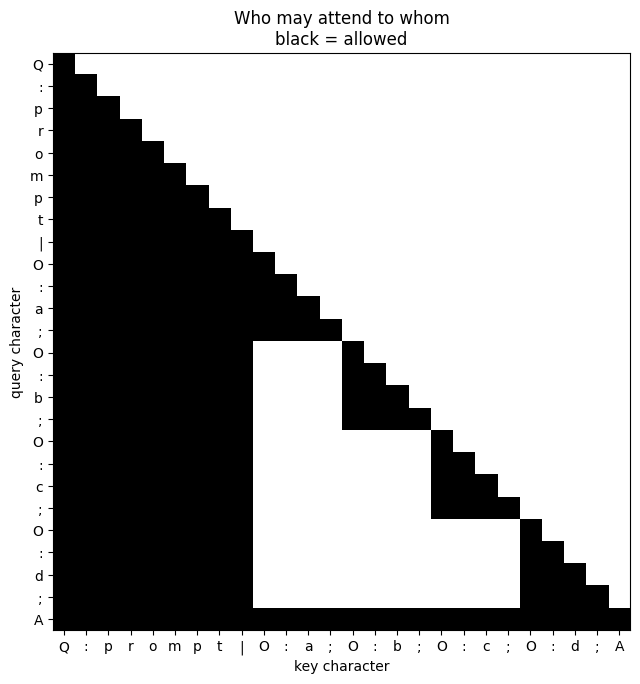

In [10]:
demo_prompt = 'Q:prompt|O:a;O:b;O:c;O:d;A'
demo_record = {
    'prompt': demo_prompt,
    'option_positions': [
        index for index, char in enumerate(demo_prompt) if char == ';'
    ],
    'label': 0,
}
demo_roles = encode_record(demo_record)['roles'][None, :].to(device)
allowed = shared_attention_mask(demo_roles, torch.float32)[0, 0].cpu()
characters = list(demo_prompt)
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(allowed, cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
ax.set_xticks(range(len(characters)), characters)
ax.set_yticks(range(len(characters)), characters)
ax.set_title('Who may attend to whom\nblack = allowed')
ax.set_xlabel('key character')
ax.set_ylabel('query character')
plt.show()


In [11]:
decision_index = demo_roles[0].tolist().index(DECIDE)
print(
    'decision character can read',
    int(allowed[decision_index].sum()),
    'earlier characters'
)

decision character can read 26 earlier characters


## Build the transformer and pointer head

The transformer creates hidden states. The pointer head compares the decision state with the four option-ending semicolons and produces four logits.


### Attention components


In [12]:
class SingleHeadAttention(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embed, head_size, bias=False)
        self.query = nn.Linear(n_embed, head_size, bias=False)
        self.value = nn.Linear(n_embed, head_size, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, attention_mask):
        key = self.key(x)
        query = self.query(x)
        value = self.value(x)

        weights = query @ key.transpose(-2, -1)
        weights = weights * self.key.out_features ** -0.5
        weights = weights.masked_fill(
            attention_mask[:, 0] == 0, float('-inf')
        )
        weights = weights.softmax(dim=-1)
        return self.dropout(weights) @ value


class MultiHeadAttention(nn.Module):
    def __init__(self, heads):
        super().__init__()
        self.heads = nn.ModuleList(
            [SingleHeadAttention(n_embed // heads) for _ in range(heads)]
        )
        self.proj = nn.Linear(n_embed, n_embed)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, attention_mask):
        joined = torch.cat(
            [head(x, attention_mask) for head in self.heads], dim=-1
        )
        return self.dropout(self.proj(joined))

### Feed-forward and residual blocks


In [13]:
class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embed, 4 * n_embed),
            nn.ReLU(),
            nn.Linear(4 * n_embed, n_embed),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.sa = MultiHeadAttention(n_head)
        self.ffwd = FeedForward()
        self.ln1 = nn.LayerNorm(n_embed)
        self.ln2 = nn.LayerNorm(n_embed)

    def forward(self, x, attention_mask):
        x = x + self.sa(self.ln1(x), attention_mask)
        return x + self.ffwd(self.ln2(x))

### Pointer head

The transformer builds the hidden states. This small head compares the decision state with the four option-terminal states and returns four logits, one per option. Here `B` is batch size, `O` is the number of options (`4` here), and `E` is the embedding dimension.


In [14]:
class PointerHead(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.query = nn.Linear(d, d, bias=False)
        self.key = nn.Linear(d, d, bias=False)
        self.scale = d ** -0.5

    def forward(self, h_decide, h_options):
        query = self.query(h_decide)[:, None, :]  # [B,E] -> [B,1,E]; B E @ E E -> B E
        key = self.key(h_options)  # [B,O,E] -> [B,O,E]; B O E @ E E -> B O E
        mul = query * key  # [B,1,E] * [B,O,E] -> [B,O,E] elementwise
        logits = mul.sum(dim=-1) * self.scale  # [B,O,E] sum over E -> [B,O]
        return logits


### Assemble the model


In [15]:
class TinyJev(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embed)
        self.pos_embedding_table = nn.Embedding(block_size, n_embed)
        self.blocks = nn.ModuleList([Block() for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(n_embed)
        self.pointer_head = PointerHead(n_embed)
        self.attention_mask = StructuredAttentionMask(block_size)

    def encode_hidden(self, input_ids, role_ids, position_ids):
        mask_dtype = (
            torch.float32
            if input_ids.device.type == 'mps'
            else self.token_embedding_table.weight.dtype
        )
        attention_mask = self.attention_mask(role_ids, mask_dtype)
        x = self.token_embedding_table(input_ids)
        x = x + self.pos_embedding_table(position_ids)
        for block in self.blocks:
            x = block(x, attention_mask)
        return self.ln_f(x)

    def forward(self, batch):
        hidden = self.encode_hidden(
            batch.input_ids, batch.role_ids, batch.position_ids
        )
        batch_indices = torch.arange(hidden.shape[0], device=hidden.device)
        decision = hidden[batch_indices, batch.decide_positions]
        options = hidden[batch_indices[:, None], batch.option_positions]
        logits = self.pointer_head(decision, options)
        loss = F.cross_entropy(logits, batch.labels)
        return logits, loss

In [16]:
torch.manual_seed(1337)
model = TinyJev().to(device)
mixed_inputs = collate(train_encoded[:2])
with torch.no_grad():
    mixed_logits, mixed_loss = model(mixed_inputs)
print(
    'mixed-batch logits:', tuple(mixed_logits.shape),
    'loss:', f'{mixed_loss.item():.4f}'
)


mixed-batch logits: (2, 4) loss: 1.3076


## Train and evaluate

Training minimizes cross-entropy over four pointer logits. The reports show overall loss and accuracy for the train monitor, validation records, and fact-OOD diagnostic.


### Evaluation helpers


In [17]:
def predict_records(
    model, records, batch_size, device, include_probabilities=False
):
    model.eval()
    prediction_rows = []
    encoded = [encode_record(row) for row in records]

    with torch.no_grad():
        for start in range(0, len(records), batch_size):
            batch_records = records[start : start + batch_size]
            packed = collate(encoded[start : start + batch_size])
            logits, _ = model(packed)
            nlls = F.cross_entropy(
                logits, packed.labels, reduction='none'
            ).cpu()
            predictions = logits.argmax(-1).cpu()
            probabilities = (
                F.softmax(logits, dim=-1).cpu()
                if include_probabilities
                else None
            )
            for row_index, (row, nll, predicted) in enumerate(
                zip(batch_records, nlls, predictions)
            ):
                prediction = {
                    'record': row,
                    'label': row['label'],
                    'nll': float(nll),
                    'predicted': int(predicted),
                    'correct': int(predicted) == row['label'],
                }
                if probabilities is not None:
                    prediction['probabilities'] = probabilities[row_index]
                prediction_rows.append(prediction)
    return prediction_rows


def evaluate_records(
    model, records, batch_size, device, include_probabilities=False
):
    rows = predict_records(
        model,
        records,
        batch_size,
        device,
        include_probabilities=include_probabilities,
    )
    total = len(rows)
    correct = sum(row['correct'] for row in rows)
    return {
        'records': total,
        'loss': sum(row['nll'] for row in rows) / total,
        'accuracy': correct / total,
        'chance_accuracy': CHANCE_ACCURACY,
        'rows': rows,
    }


In [18]:
monitor = random.Random(2025).sample(train_records, 512)


def report(name, records, include_probabilities=False):
    result = evaluate_records(
        model,
        records,
        batch_size,
        device,
        include_probabilities=include_probabilities,
    )
    print(
        f"{name}: records={result['records']}, NLL={result['loss']:.4f}, "
        f"accuracy={result['accuracy']:.1%}, "
        f"chance={result['chance_accuracy']:.1%}"
    )
    return result

### Training loop

The default cell runs 1,500 updates. A smoke run can replace that count with one update.


In [19]:
print('Untrained metrics:')
report('train monitor', monitor)
report('validation', validation_records)

train_rng = random.Random(1337)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
for update in range(1, max_iterations + 1):
    model.train()
    inputs = get_batch(train_encoded, batch_size, train_rng)
    _, loss = model(inputs)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    last_loss = loss.item()
    if update == 1:
        print(f'update 1/{max_iterations}: loss={last_loss:.4f}')
    if update % eval_interval == 0 or update == max_iterations:
        print('\n')
        print(
            f'update {update}/{max_iterations}: '
            f'last minibatch loss={last_loss:.4f}'
        )
        report('train monitor', monitor)
        report('validation', validation_records)

Untrained metrics:
train monitor: records=512, NLL=1.3730, accuracy=30.3%, chance=25.0%
validation: records=720, NLL=1.3938, accuracy=29.7%, chance=25.0%
update 1/1500: loss=1.4454


update 250/1500: last minibatch loss=0.7321
train monitor: records=512, NLL=0.7028, accuracy=73.0%, chance=25.0%
validation: records=720, NLL=0.7683, accuracy=70.1%, chance=25.0%


update 500/1500: last minibatch loss=0.2913
train monitor: records=512, NLL=0.1678, accuracy=95.3%, chance=25.0%
validation: records=720, NLL=0.2413, accuracy=91.8%, chance=25.0%


update 750/1500: last minibatch loss=0.1593
train monitor: records=512, NLL=0.0667, accuracy=97.3%, chance=25.0%
validation: records=720, NLL=0.1350, accuracy=95.6%, chance=25.0%


update 1000/1500: last minibatch loss=0.2116
train monitor: records=512, NLL=0.0727, accuracy=97.9%, chance=25.0%
validation: records=720, NLL=0.0837, accuracy=96.8%, chance=25.0%


update 1250/1500: last minibatch loss=0.1230
train monitor: records=512, NLL=0.0265, accurac

### Final metrics and qualitative predictions

The final reports always include validation metrics. Fact-OOD is an optional secondary diagnostic, disabled by default. The notebook then prints two reproducibly selected validation examples from each domain.


In [20]:
report('Final train monitor', monitor)
final_validation = report(
    'Final validation', validation_records, include_probabilities=True
)
if RUN_FACT_OOD:
    report('Final fact-OOD diagnostic', fact_ood_records)


def print_predictions(name, prediction_rows, indices):
    print('\n' + name)
    for index in indices:
        prediction = prediction_rows[index]
        row = prediction['record']
        probabilities = prediction['probabilities']
        mappings = ', '.join(
            f'{option_id}: {option} -> {float(prob):.3f}'
            for option_id, (option, prob) in enumerate(
                zip(row['options'], probabilities)
            )
        )
        print(
            f"{row['prompt']}\n  {mappings}\n"
            f"  correct={prediction['label']}, predicted={prediction['predicted']}, "
            f"correct? {prediction['correct']}"
        )
        print('\n')


# Pick two fresh validation examples from each domain.
QUALITATIVE_EXAMPLES_PER_DOMAIN = 2


def select_qualitative_indices(records):
    sampler = random.Random(2025)
    sample_indices = []
    for domain in DOMAIN_NAMES:
        domain_indices = [
            index
            for index, row in enumerate(records)
            if row['domain'] == domain
        ]
        sample_indices.extend(
            sampler.sample(domain_indices, QUALITATIVE_EXAMPLES_PER_DOMAIN)
        )
    return sample_indices


sample_indices = select_qualitative_indices(validation_records)
print_predictions(
    'Balanced qualitative validation sample',
    final_validation['rows'],
    sample_indices,
)
print(
    'Interpretation: validation shares facts with training but uses disjoint prompts; '
    'fact-OOD is an optional secondary diagnostic using unseen facts.'
)


Final train monitor: records=512, NLL=0.0168, accuracy=99.4%, chance=25.0%
Final validation: records=720, NLL=0.0516, accuracy=98.2%, chance=25.0%

Balanced qualitative validation sample
Q:select the answer for india and capital|O:berlin;O:london;O:new delhi;O:lisbon;A
  0: berlin -> 0.000, 1: london -> 0.000, 2: new delhi -> 1.000, 3: lisbon -> 0.000
  correct=2, predicted=2, correct? True


Q:a question about belgium and capital|O:london;O:brussels;O:berlin;O:lisbon;A
  0: london -> 0.000, 1: brussels -> 1.000, 2: berlin -> 0.000, 3: lisbon -> 0.000
  correct=1, predicted=1, correct? True


Q:which answer is associated with insulator and contains|O:vacuum;O:bound charges;O:toward center;O:work per time;A
  0: vacuum -> 0.001, 1: bound charges -> 0.998, 2: toward center -> 0.001, 3: work per time -> 0.000
  correct=1, predicted=1, correct? True


Q:select the answer for temperature and measures|O:electromagnetic waves;O:distance between crests;O:average kinetic energy;O:directed dista